# Hotel Booking Demand — Exploratory Data Analysis (EDA)

This notebook examines demand, guest origins, ADR/pricing, seasonality, guest preferences, market segments & distribution channels, length of stay, and cancellations. The analysis uses cleaned booking records and explicitly separates **non-cancelled bookings** for demand/pricing/customer analyses from **all bookings** for cancellation analysis.


## 1. Imports and setup

In [7]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

MONTHS = ['January','February','March','April','May','June','July','August','September','October','November','December']

## 2. Load data and initial inspection

In [ ]:

df_raw = pd.read_csv('hotel_bookings.csv')

In [9]:
print(f'Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}')

Rows: 119,390 | Columns: 32


In [11]:
# Display first 5 rows 

display(df_raw.head())


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015


In [12]:
# Display last 5 rows
display(df_raw.tail())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,9/6/2017
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,9/7/2017
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,9/7/2017
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,9/7/2017
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,9/7/2017


In [13]:
# Column names
print("\nColumn Names:")
print(df_raw.columns.tolist())


Column Names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


In [24]:
# Data types
print("\nData Types:")
display(df_raw.dtypes)


Data Types:


hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

In [15]:
# Dataset information
print("\nDataset Info:")
df_raw.info()



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  m

In [16]:
# Statistical summary of numerical columns
print("\nStatistical Summary:")
display(df_raw.describe())


Statistical Summary:


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [18]:
# Statistical summary of categorical columns
print("\nCategorical Summary:")
display(df_raw.describe(include="object"))



Categorical Summary:


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,10/21/2015
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [19]:
# Missing values in each column
print("\nMissing Values:")
missing_values = df_raw.isnull().sum()
display(missing_values[missing_values > 0].sort_values(ascending=False))


Missing Values:


company     112593
agent        16340
country        488
children         4
dtype: int64

In [21]:
# Missing value percentage
print("\nMissing Value Percentage:")
missing_percentage = (df_raw.isnull().sum() / len(df_raw)) * 100
display(missing_percentage[missing_percentage > 0].sort_values(ascending=False))


Missing Value Percentage:


company     94.306893
agent       13.686238
country      0.408744
children     0.003350
dtype: float64

In [22]:
# Duplicate rows
print("\nDuplicate Rows:", df_raw.duplicated().sum())


Duplicate Rows: 31994


## 3. Cleaning and analysis-ready datasets

**Cleaning decisions:** remove exact duplicate rows to avoid repeated records inflating counts; fill the four missing `children` values with 0 (no child count recorded); retain missing `agent` and `company` because they are identifiers and not needed for the core questions; keep missing `country` rows for other analyses but exclude them from country-origin summaries; exclude cancelled bookings from the demand/pricing/preference analyses. No global ADR outlier deletion is applied; price plots use non-negative ADR and a 99th percentile cap for readability, with the cap noted in charts.

In [25]:
df = df_raw.drop_duplicates().copy()

In [26]:
# Children count is a small numeric guest count; missing values are treated as zero.
df['children'] = df['children'].fillna(0)

In [27]:

# Convert month labels into ordered categorical values for chart/table sorting.
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=MONTHS, ordered=True)

In [28]:
# Derived features used throughout the analysis.
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']

In [34]:
# Non-cancelled bookings for demand, guest profile and pricing analyses.
bookings = df.loc[df['is_canceled'] == 0].copy()

In [29]:

print('Rows after exact duplicate removal:', f'{len(df):,}')

Rows after exact duplicate removal: 87,396


In [30]:

print('Rows removed as duplicates:', f'{len(df_raw)-len(df):,}')

Rows removed as duplicates: 31,994


In [35]:
print('Missing values after cleaning:')
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame('missing_count'))
print('All booking rows:', f'{len(df):,}', '| Non-cancelled bookings:', f'{len(bookings):,}')

Missing values after cleaning:


,missing_count
company,82137
agent,12193
country,452
hotel,0
days_in_waiting_list,0
assigned_room_type,0
booking_changes,0
deposit_type,0
customer_type,0
previous_bookings_not_canceled,0


All booking rows: 87,396 | Non-cancelled bookings: 63,371


## 4. Executive summary — headline metrics

In [36]:
summary = pd.DataFrame({
    'Metric':['Total cleaned bookings','Non-cancelled bookings','Cancelled bookings','Cancellation rate','City Hotel bookings (non-cancelled)','Resort Hotel bookings (non-cancelled)','Overall non-cancelled ADR'],
    'Value':[len(df),len(bookings),int(df.is_canceled.sum()),df.is_canceled.mean(),
             int((bookings.hotel=='City Hotel').sum()),int((bookings.hotel=='Resort Hotel').sum()),bookings.adr.mean()]
})
display(summary)

,Metric,Value
0,Total cleaned bookings,87396.000000
1,Non-cancelled bookings,63371.000000
2,Cancelled bookings,24025.000000
3,Cancellation rate,0.274898
4,City Hotel bookings (non-cancelled),37379.000000
5,Resort Hotel bookings (non-cancelled),25992.000000
6,Overall non-cancelled ADR,102.001961


In [ ]:
summary = pd.DataFrame({
    'Metric':['Total cleaned bookings','Non-cancelled bookings','Cancelled bookings','Cancellation rate','City Hotel bookings (non-cancelled)','Resort Hotel bookings (non-cancelled)','Overall non-cancelled ADR'],
    'Value':[len(df),len(bookings),int(df.is_canceled.sum()),df.is_canceled.mean(),
             int((bookings.hotel=='City Hotel').sum()),int((bookings.hotel=='Resort Hotel').sum()),bookings.adr.mean()]
})
display(summary)
hotel_summary = bookings.groupby('hotel').agg(non_cancelled_bookings=('hotel','size'), average_adr=('adr','mean'), median_adr=('adr','median'), average_nights=('total_nights','mean'), avg_special_requests=('total_of_special_requests','mean')).sort_values('non_cancelled_bookings',ascending=False)
display(hotel_summary.round(2))

,non_cancelled_bookings,average_adr,median_adr,average_nights,avg_special_requests
hotel,,,,,
City Hotel,37379,108.28,102.00,2.99,0.8
Resort Hotel,25992,92.97,74.25,4.20,0.7


## 5. Guest origins — top countries and geographic view

Country counts use **non-cancelled booking records** with a non-missing country value. A booking record is used as the unit of count, not a deduplicated traveler.

In [77]:
country_counts = (
    bookings.dropna(subset=['country'])
    .groupby('country')
    .size()
    .sort_values(ascending=False)
)

top_countries = (
    country_counts.head(15)
    .rename('booking_count')
    .reset_index()
)

display(top_countries)

,country,booking_count
0,PRT,17662
1,GBR,8448
2,FRA,7104
3,ESP,5390
4,DEU,4334
5,IRL,2348
6,ITA,1991
7,BEL,1670
8,NLD,1561
9,USA,1416


In [91]:
# Top 5 European countries share of non-cancelled bookings (with known country)
top5_eu = ['PRT', 'GBR', 'FRA', 'ESP', 'DEU']
known_country_bookings = bookings.dropna(subset=['country'])
top5_eu_count = known_country_bookings['country'].isin(top5_eu).sum()
top5_eu_share = known_country_bookings['country'].isin(top5_eu).mean() * 100

print(f"Top 5 European countries ({', '.join(top5_eu)}): {top5_eu_count:,} of {len(known_country_bookings):,} non-cancelled bookings ({top5_eu_share:.2f}%)")

Top 5 European countries (PRT, GBR, FRA, ESP, DEU): 42,938 of 62,953 non-cancelled bookings (68.21%)


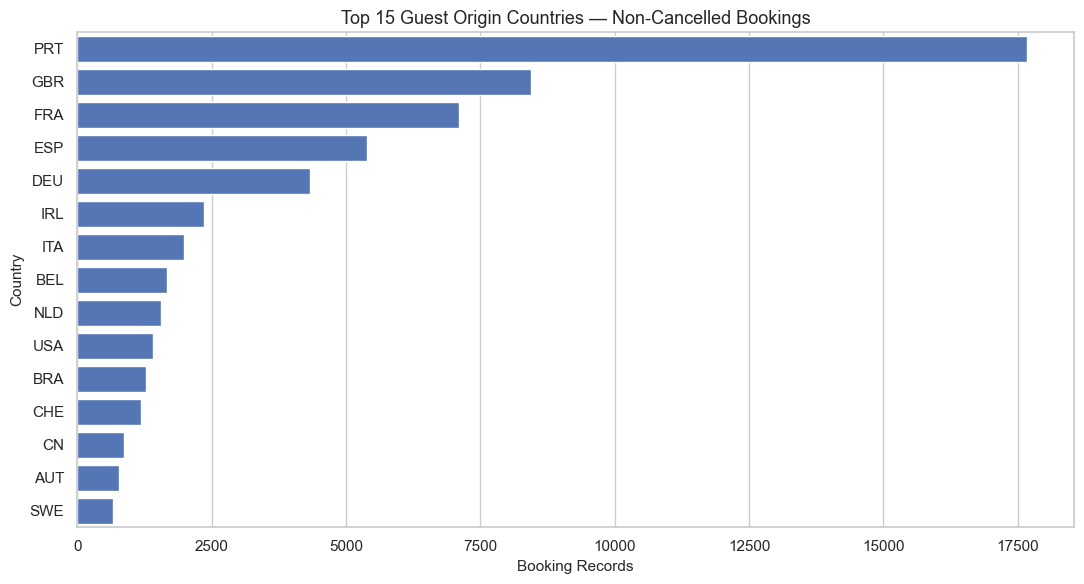

In [78]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_countries,
    y='country',
    x='booking_count',
    color='#4472C4'
)

plt.title('Top 15 Guest Origin Countries — Non-Cancelled Bookings')
plt.xlabel('Booking Records')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

In [87]:


# Choropleth: convert ISO alpha-2 codes (hotel dataset) to alpha-3 codes for Plotly.
try:
    import pycountry
    import plotly.express as px
    country_map = {}
    for code in country_counts.index:
        try: country_map[code] = pycountry.countries.get(alpha_2=code).alpha_3
        except Exception: pass
    map_df = country_counts.rename('bookings').reset_index().rename(columns={'country':'country_code'})
    map_df['iso3'] = map_df['country_code'].map(country_map)
    map_df = map_df.dropna(subset=['iso3'])
    fig = px.choropleth(map_df, locations='iso3', color='bookings', hover_name='country_code',
                        color_continuous_scale='Blues', title='Guest origin countries — non-cancelled bookings',
                        labels={'bookings':'Booking records'})
    fig.show()
except Exception as e:
    print('Map rendering unavailable in this environment:',e)

Map rendering unavailable in this environment: No module named 'pycountry'


## 6. ADR (Average Daily Rate) — City vs Resort and room types

ADR comparisons use non-cancelled records. For distribution charts, values above the non-cancelled ADR 99th percentile are clipped for visualization only; summary tables use the full cleaned data.

In [41]:
# Filter out negative ADR values
adr_valid = bookings.loc[bookings.adr >= 0].copy()

In [42]:
# Calculate the 99th percentile of ADR
adr_cap = adr_valid.adr.quantile(.99)

# Keep ADR values below the 99th percentile for plotting
adr_plot = adr_valid.loc[adr_valid.adr <= adr_cap]

print(f'99th percentile ADR used as visual cap: {adr_cap:.2f} (charts only)')

99th percentile ADR used as visual cap: 258.00 (charts only)


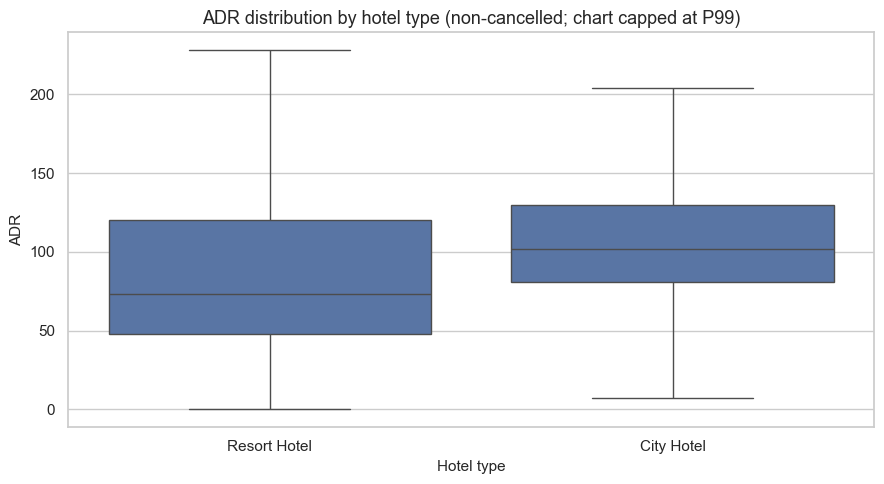

In [43]:
# Plot ADR distribution for City Hotel vs Resort Hotel
plt.figure(figsize=(9,5))

sns.boxplot(
    data=adr_plot,
    x='hotel',
    y='adr',
    showfliers=False
)

plt.title('ADR distribution by hotel type (non-cancelled; chart capped at P99)')
plt.xlabel('Hotel type')
plt.ylabel('ADR')
plt.tight_layout()
plt.show()

In [44]:
# Average and median ADR by hotel type
display(
    adr_valid.groupby('hotel')['adr']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

,count,mean,median
hotel,,,
City Hotel,37379,108.28,102.00
Resort Hotel,25991,92.97,74.25


## 7. Monthly ADR and seasonality

Month order is explicitly January–December. Monthly ADR is calculated from non-cancelled bookings.

In [45]:
# Calculate monthly average ADR for each hotel
monthly_adr = bookings.groupby(
    ['hotel', 'arrival_date_month'],
    observed=False
)['adr'].mean().reset_index()

In [46]:
# Define months in correct calendar order
MONTHS = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

# Convert month column to ordered categorical
monthly_adr['arrival_date_month'] = pd.Categorical(
    monthly_adr['arrival_date_month'],
    categories=MONTHS,
    ordered=True
)

# Sort by calendar month
monthly_adr = monthly_adr.sort_values('arrival_date_month')

In [47]:
# Compare monthly ADR between City Hotel and Resort Hotel
monthly_adr_pivot = monthly_adr.pivot(
    index='arrival_date_month',
    columns='hotel',
    values='adr'
)

display(monthly_adr_pivot.round(2))

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,83.18,48.54
February,87.84,53.62
March,90.76,57.08
April,114.12,76.84
May,124.53,77.73
June,120.49,108.97
July,119.74,150.91
August,122.50,182.10
September,116.72,98.86


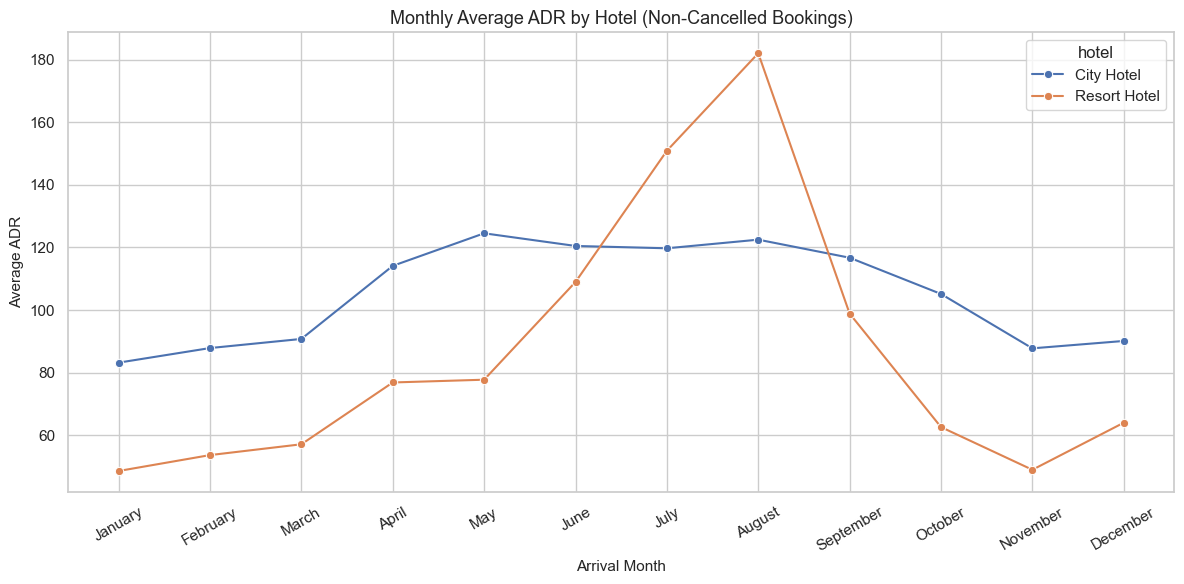

In [48]:
# Plot monthly average ADR trends
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_adr,
    x='arrival_date_month',
    y='adr',
    hue='hotel',
    marker='o'
)

plt.title('Monthly Average ADR by Hotel (Non-Cancelled Bookings)')
plt.xlabel('Arrival Month')
plt.ylabel('Average ADR')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 8. Meal preferences by hotel

Meal counts are based on non-cancelled booking records. Meal codes are retained as the dataset uses them: `BB`, `HB`, `FB`, `SC`, and `Undefined`.

In [49]:
# Calculate meal plan bookings for each hotel
meal_counts = bookings.groupby(['hotel', 'meal']).size().rename('bookings').reset_index()

display(meal_counts)

,hotel,meal,bookings
0,City Hotel,BB,29358
1,City Hotel,FB,9
2,City Hotel,HB,1959
3,City Hotel,SC,6053
4,Resort Hotel,BB,20573
5,Resort Hotel,FB,252
6,Resort Hotel,HB,4676
7,Resort Hotel,SC,81
8,Resort Hotel,Undefined,410


In [50]:
# Compare meal counts between City Hotel and Resort Hotel
meal_pivot = meal_counts.pivot(
    index='meal',
    columns='hotel',
    values='bookings'
)

# Replace missing values with 0 and convert to integers
meal_pivot = meal_pivot.fillna(0).astype(int)

display(meal_pivot)

hotel,City Hotel,Resort Hotel
meal,,
BB,29358,20573
FB,9,252
HB,1959,4676
SC,6053,81
Undefined,0,410


In [90]:
# Meal plan percentage share overall and within each hotel (non-cancelled)
meal_overall_pct = (bookings['meal'].value_counts(normalize=True) * 100).rename('Overall (%)')
meal_hotel_pct = pd.crosstab(bookings['meal'], bookings['hotel'], normalize='columns') * 100
meal_share_summary = meal_hotel_pct.join(meal_overall_pct).round(2)

display(meal_share_summary)

,City Hotel,Resort Hotel,Overall (%)
meal,,,
BB,78.54,79.15,78.79
FB,0.02,0.97,0.41
HB,5.24,17.99,10.47
SC,16.19,0.31,9.68
Undefined,0.00,1.58,0.65


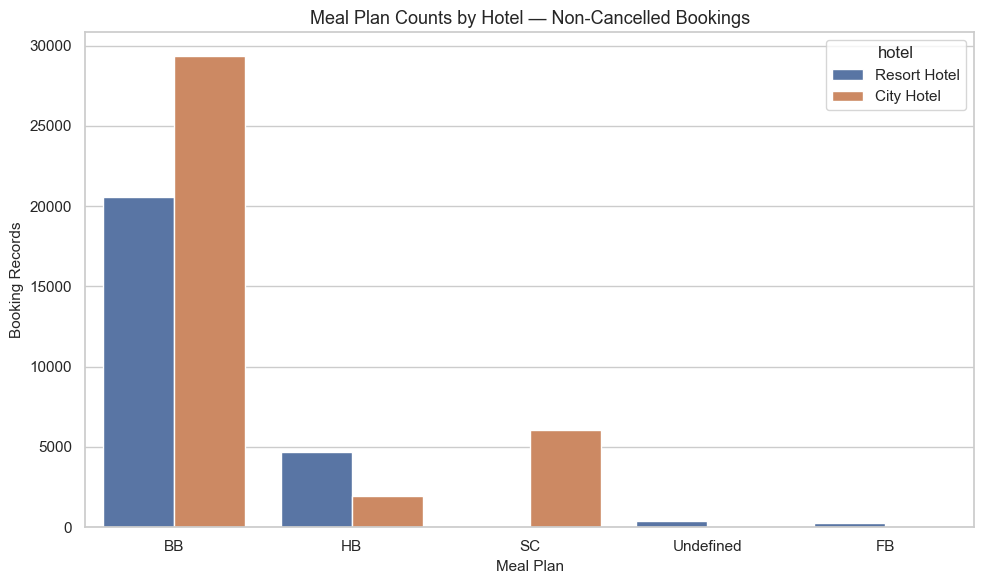

In [51]:
# Plot meal plan counts by hotel
plt.figure(figsize=(10, 6))

sns.countplot(
    data=bookings,
    x='meal',
    hue='hotel',
    order=bookings.meal.value_counts().index
)

plt.title('Meal Plan Counts by Hotel — Non-Cancelled Bookings')
plt.xlabel('Meal Plan')
plt.ylabel('Booking Records')
plt.tight_layout()
plt.show()

## 9. Special requests and cancellation behavior

This section uses all cleaned booking records (cancelled and non-cancelled). The pivot is booking count by number of special requests and cancellation outcome; the heatmap shows counts. Cancellation rates are also calculated within request-count groups to avoid interpreting raw counts alone.

In [52]:
# Create a cross-tabulation of special requests and cancellation status
request_pivot = pd.crosstab(
    df['total_of_special_requests'],
    df['is_canceled']
).rename(columns={0: 'Not cancelled', 1: 'Cancelled'})

display(request_pivot)

is_canceled,Not cancelled,Cancelled
total_of_special_requests,,
0,29320,14574
1,22514,6503
2,9297,2515
3,1920,397
4,286,34
5,34,2


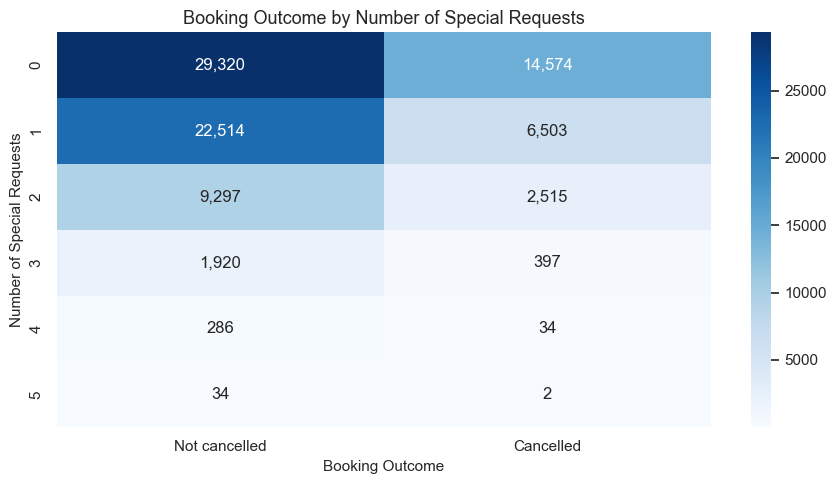

In [53]:
# Plot booking outcomes by number of special requests
plt.figure(figsize=(9, 5))

sns.heatmap(
    request_pivot,
    annot=True,
    fmt=',',
    cmap='Blues'
)

plt.title('Booking Outcome by Number of Special Requests')
plt.xlabel('Booking Outcome')
plt.ylabel('Number of Special Requests')
plt.tight_layout()
plt.show()

In [54]:
# Calculate booking count and cancellation rate by special requests
request_rate = (
    df.groupby('total_of_special_requests')['is_canceled']
    .agg(['count', 'mean'])
    .reset_index()
    .rename(columns={
        'count': 'bookings',
        'mean': 'cancellation_rate'
    })
)

display(request_rate.round(3))

,total_of_special_requests,bookings,cancellation_rate
0,0,43894,0.332
1,1,29017,0.224
2,2,11812,0.213
3,3,2317,0.171
4,4,320,0.106
5,5,36,0.056


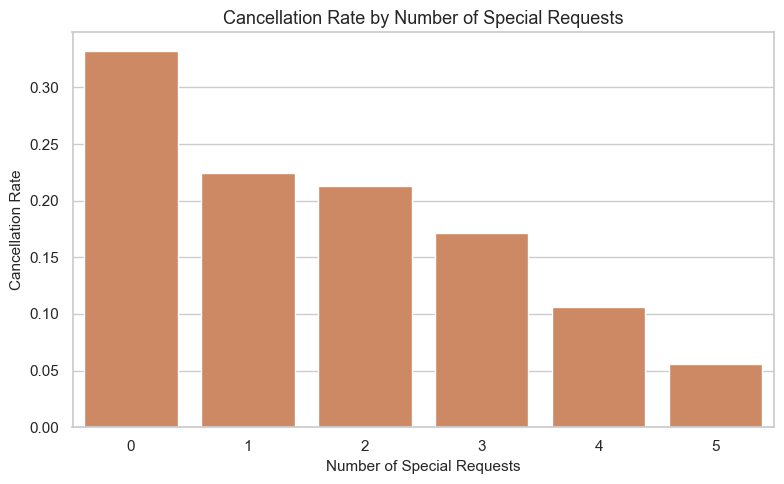

In [55]:
# Plot cancellation rate by number of special requests
plt.figure(figsize=(8, 5))

sns.barplot(
    data=request_rate,
    x='total_of_special_requests',
    y='cancellation_rate',
    color='#DD8452'
)

plt.title('Cancellation Rate by Number of Special Requests')
plt.xlabel('Number of Special Requests')
plt.ylabel('Cancellation Rate')
plt.tight_layout()
plt.show()

## 10. Busiest arrival months — demand volume by hotel

Counts include non-cancelled bookings only, so they reflect realized booking volume rather than total booked demand before cancellations. Months are ordered by calendar sequence.

In [56]:
# Calculate monthly non-cancelled booking volume for each hotel
monthly_volume = (
    bookings.groupby(['hotel', 'arrival_date_month'], observed=False)
    .size()
    .rename('bookings')
    .reset_index()
)

display(monthly_volume.head())

,hotel,arrival_date_month,bookings
0,City Hotel,January,1966
1,City Hotel,February,2630
2,City Hotel,March,3491
3,City Hotel,April,3330
4,City Hotel,May,3667


In [57]:
# Arrange months in correct calendar order
monthly_volume['arrival_date_month'] = pd.Categorical(
    monthly_volume['arrival_date_month'],
    categories=MONTHS,
    ordered=True
)

# Sort data by month
monthly_volume = monthly_volume.sort_values('arrival_date_month')

display(monthly_volume.head(12))

,hotel,arrival_date_month,bookings
0,City Hotel,January,1966
12,Resort Hotel,January,1689
1,City Hotel,February,2630
13,Resort Hotel,February,2053
2,City Hotel,March,3491
14,Resort Hotel,March,2192
3,City Hotel,April,3330
15,Resort Hotel,April,2169
4,City Hotel,May,3667
16,Resort Hotel,May,2246


In [58]:
# Compare monthly booking volume between City Hotel and Resort Hotel
volume_pivot = monthly_volume.pivot(
    index='arrival_date_month',
    columns='hotel',
    values='bookings'
)

# Replace missing values with 0 and convert to integers
volume_pivot = volume_pivot.fillna(0).astype(int)

display(volume_pivot)

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,1966,1689
February,2630,2053
March,3491,2192
April,3330,2169
May,3667,2246
June,3484,1927
July,3846,3013
August,4481,3153
September,3173,1875


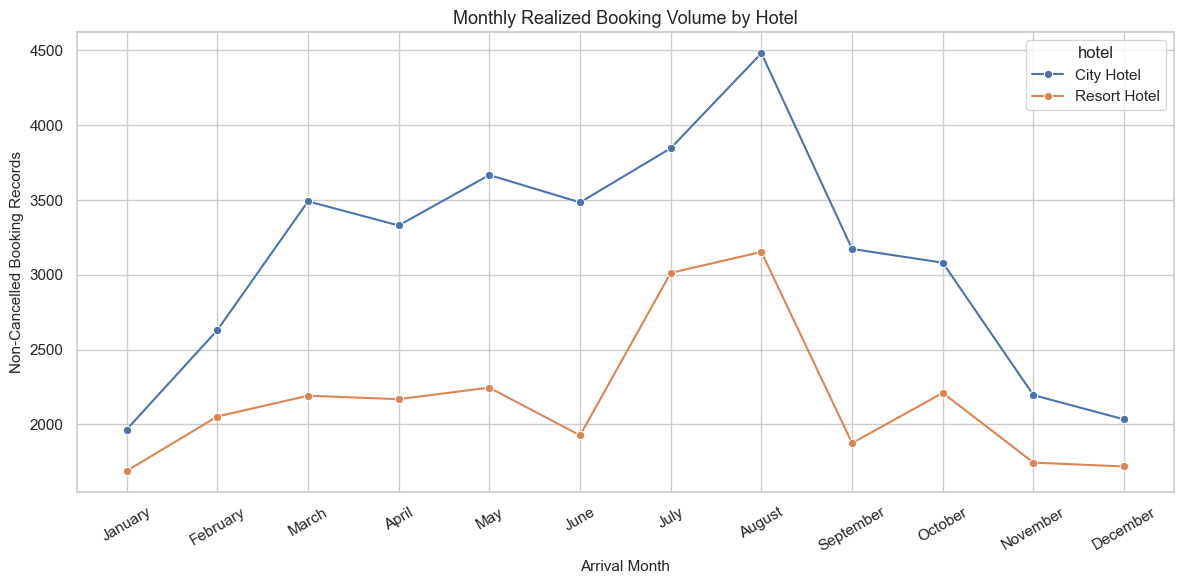

In [59]:
# Plot monthly realized booking volume
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_volume,
    x='arrival_date_month',
    y='bookings',
    hue='hotel',
    marker='o'
)

plt.title('Monthly Realized Booking Volume by Hotel')
plt.xlabel('Arrival Month')
plt.ylabel('Non-Cancelled Booking Records')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 11. Length of stay

Compare booking nights across hotels using non-cancelled records. The distribution is capped at the 99th percentile for visualization only; mean/median summaries retain all values.

In [60]:
# Create total_nights by combining weekend and weekday stays
bookings['total_nights'] = (
    bookings['stays_in_weekend_nights'] +
    bookings['stays_in_week_nights']
)

display(bookings[['stays_in_weekend_nights', 'stays_in_week_nights', 'total_nights']].head())

,stays_in_weekend_nights,stays_in_week_nights,total_nights
0,0,0,0
1,0,0,0
2,0,1,1
3,0,1,1
4,0,2,2


In [61]:
# Calculate length-of-stay summary statistics by hotel
stay_summary = (
    bookings.groupby('hotel')['total_nights']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

display(stay_summary)

,count,mean,median
hotel,,,
City Hotel,37379,2.99,3.0
Resort Hotel,25992,4.20,3.0


In [62]:
# Calculate the 99th percentile of total nights
stay_cap = bookings['total_nights'].quantile(.99)

# Filter stays up to the 99th percentile for visualization
stay_plot = bookings[bookings['total_nights'] <= stay_cap]

print(f'Visual cap at 99th percentile: {stay_cap:.0f} nights')

Visual cap at 99th percentile: 14 nights


In [ ]:
# Plot length-of-stay distribution by hotel
plt.figure(figsize=(10, 5))

sns.histplot(
    data=stay_plot,
    x='total_nights',
    hue='hotel',
    bins=35,
    element='step',
    stat='count',
    common_norm=False
)

plt.title(f'Length-of-Stay Distribution by Hotel (Visual Cap at P99 = {stay_cap:.0f} Nights)')
plt.xlabel('Total Nights')
plt.ylabel('Booking Records')
plt.tight_layout()
plt.show()

In [89]:
# Exact stay duration counts (1 to 15 nights) highlighting 7- and 14-night peaks at Resort Hotel
stay_dist_table = (
    bookings[bookings['total_nights'].between(1, 15)]
    .groupby(['total_nights', 'hotel'])
    .size()
    .unstack(fill_value=0)
)
display(stay_dist_table)

hotel,City Hotel,Resort Hotel
total_nights,,
1,7986,6037
2,7639,3901
3,9306,3185
4,6533,2902
5,2914,1780
6,1030,1113
7,1155,4063
8,199,469
9,112,394


## 12. Market segment analysis

Market-segment counts and ADR use non-cancelled bookings. ADR comparison is descriptive; segment mix and hotel differences may confound price comparisons.

In [63]:
# Calculate booking volume for each market segment
segment_counts = (
    bookings.groupby('market_segment')
    .size()
    .sort_values(ascending=False)
    .rename('booking_count')
    .reset_index()
)

display(segment_counts)

,market_segment,booking_count
0,Online TA,33373
1,Offline TA/TO,11826
2,Direct,10067
3,Corporate,3702
4,Groups,3607
5,Complementary,614
6,Aviation,182


In [ ]:
# Plot booking volume by market segment
plt.figure(figsize=(10, 5))

sns.barplot(
    data=segment_counts,
    x='booking_count',
    y='market_segment',
    color='#55A868'
)

plt.title('Non-Cancelled Booking Volume by Market Segment')
plt.xlabel('Booking Records')
plt.ylabel('Market Segment')
plt.tight_layout()
plt.show()

In [64]:
# Calculate ADR statistics by market segment and hotel type
segment_adr = (
    bookings.groupby(['market_segment', 'hotel'])['adr']
    .agg(['count', 'mean', 'median'])
    .reset_index()
    .sort_values('mean', ascending=False)
)

display(segment_adr.round(2))

,market_segment,hotel,count,mean,median
5,Direct,City Hotel,4647,120.36,112.50
11,Online TA,City Hotel,22376,118.19,112.59
6,Direct,Resort Hotel,5420,110.10,90.81
12,Online TA,Resort Hotel,10997,107.46,88.22
0,Aviation,City Hotel,182,100.08,95.00
9,Offline TA/TO,City Hotel,6010,85.62,82.40
7,Groups,City Hotel,1745,85.43,75.33
3,Corporate,City Hotel,1963,81.75,75.00
10,Offline TA/TO,Resort Hotel,5816,74.26,64.90
8,Groups,Resort Hotel,1862,64.03,61.00


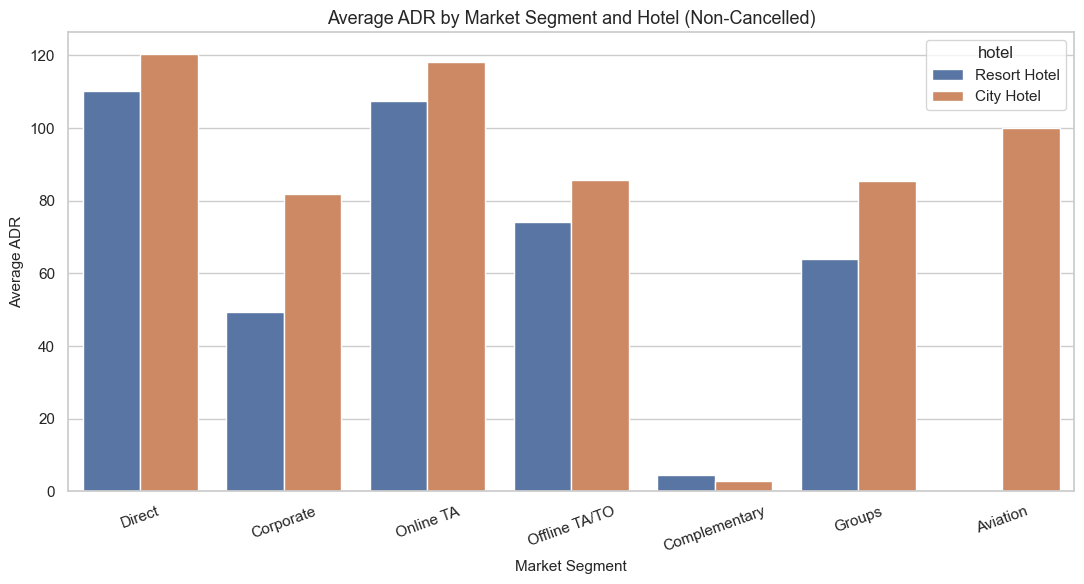

In [65]:
# Plot average ADR by market segment and hotel type
plt.figure(figsize=(11, 6))

sns.barplot(
    data=bookings,
    x='market_segment',
    y='adr',
    hue='hotel',
    estimator=np.mean,
    errorbar=None
)

plt.title('Average ADR by Market Segment and Hotel (Non-Cancelled)')
plt.xlabel('Market Segment')
plt.ylabel('Average ADR')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [88]:
# Market segment share and overall ADR (non-cancelled)
segment_share_adr = (
    bookings.groupby('market_segment')
    .agg(
        booking_count=('market_segment', 'size'),
        share_pct=('market_segment', lambda s: len(s) / len(bookings) * 100),
        mean_adr=('adr', 'mean'),
        median_adr=('adr', 'median')
    )
    .sort_values('booking_count', ascending=False)
    .round(2)
)
display(segment_share_adr)

# Distribution channel share and ADR (intermediaries vs Direct)
channel_share_adr = (
    bookings.groupby('distribution_channel')
    .agg(
        booking_count=('distribution_channel', 'size'),
        share_pct=('distribution_channel', lambda s: len(s) / len(bookings) * 100),
        mean_adr=('adr', 'mean'),
        median_adr=('adr', 'median')
    )
    .sort_values('booking_count', ascending=False)
    .round(2)
)
display(channel_share_adr)

intermediary_share = (
    bookings['market_segment'].isin(['Online TA', 'Offline TA/TO']).mean() * 100
)
print(f"Online TA share: {segment_share_adr.loc['Online TA', 'share_pct']:.2f}%")
print(f"Overall intermediaries share (Online TA + Offline TA/TO): {intermediary_share:.2f}% (TA/TO channel: {channel_share_adr.loc['TA/TO', 'share_pct']:.2f}%)")

,booking_count,share_pct,mean_adr,median_adr
market_segment,,,,
Online TA,33373,52.66,114.66,108.00
Offline TA/TO,11826,18.66,80.03,76.50
Direct,10067,15.89,114.83,104.98
Corporate,3702,5.84,66.59,65.00
Groups,3607,5.69,74.38,68.00
Complementary,614,0.97,3.23,0.00
Aviation,182,0.29,100.08,95.00


,booking_count,share_pct,mean_adr,median_adr
distribution_channel,,,,
TA/TO,47729,75.32,103.92,96.3
Direct,11063,17.46,107.48,98.0
Corporate,4433,7.00,67.06,65.0
GDS,145,0.23,119.73,113.0
Undefined,1,0.00,112.70,112.7


Online TA share: 52.66%
Overall intermediaries share (Online TA + Offline TA/TO): 71.32% (TA/TO channel: 75.32%)


## 13. Cancellation analysis — overall, hotel and month

Cancellation metrics use all cleaned booking rows. The monthly cancellation count is grouped by arrival month and sorted in calendar order.

In [66]:
# Calculate overall cancellation rate
overall_cancel_rate = df['is_canceled'].mean()

# Print total bookings, cancellations, and cancellation rate
print(
    f'Bookings: {len(df):,} | '
    f'Cancelled: {int(df["is_canceled"].sum()):,} | '
    f'Cancellation rate: {overall_cancel_rate:.1%}'
)

Bookings: 87,396 | Cancelled: 24,025 | Cancellation rate: 27.5%


In [67]:
# Calculate cancellation statistics by hotel type
by_hotel_cancel = (
    df.groupby('hotel')['is_canceled']
    .agg(['count', 'sum', 'mean'])
    .rename(columns={
        'count': 'total_bookings',
        'sum': 'cancelled_bookings',
        'mean': 'cancellation_rate'
    })
    .sort_values('cancellation_rate', ascending=False)
)

display(by_hotel_cancel.round(3))

,total_bookings,cancelled_bookings,cancellation_rate
hotel,,,
City Hotel,53428,16049,0.300
Resort Hotel,33968,7976,0.235


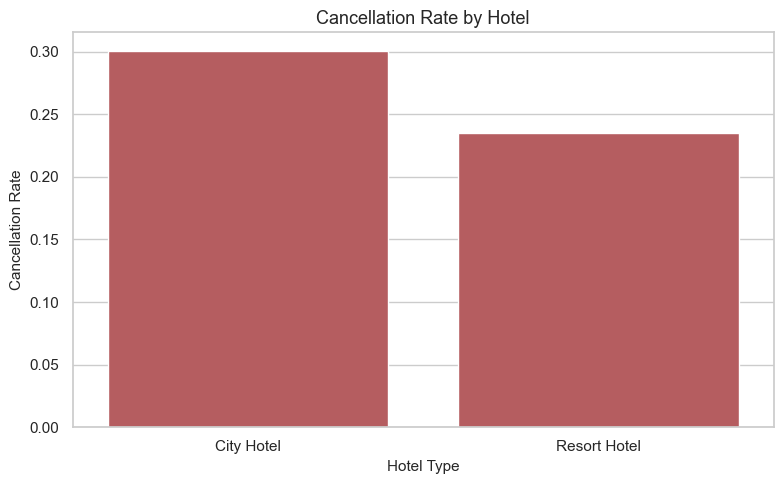

In [68]:
# Plot cancellation rate by hotel
plt.figure(figsize=(8, 5))

plot_cancel = by_hotel_cancel.reset_index()

sns.barplot(
    data=plot_cancel,
    x='hotel',
    y='cancellation_rate',
    color='#C44E52'
)

plt.title('Cancellation Rate by Hotel')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate')
plt.tight_layout()
plt.show()

In [69]:
# Filter cancelled bookings and calculate monthly cancellations by hotel
cancel_month = (
    df[df['is_canceled'] == 1]
    .groupby(['hotel', 'arrival_date_month'], observed=False)
    .size()
    .rename('cancelled_bookings')
    .reset_index()
)

display(cancel_month.head())

,hotel,arrival_date_month,cancelled_bookings
0,City Hotel,January,764
1,City Hotel,February,975
2,City Hotel,March,1365
3,City Hotel,April,1750
4,City Hotel,May,1746


In [70]:
# Arrange months in calendar order
cancel_month['arrival_date_month'] = pd.Categorical(
    cancel_month['arrival_date_month'],
    categories=MONTHS,
    ordered=True
)

# Sort cancellation data by month
cancel_month = cancel_month.sort_values('arrival_date_month')

# Create monthly cancellation comparison table
cancel_pivot = cancel_month.pivot(
    index='arrival_date_month',
    columns='hotel',
    values='cancelled_bookings'
)

# Fill missing values and convert to integers
cancel_pivot = cancel_pivot.fillna(0).astype(int)

display(cancel_pivot)

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,764,274
February,975,440
March,1365,465
April,1750,659
May,1746,696
June,1521,833
July,1898,1300
August,2110,1513
September,1067,575


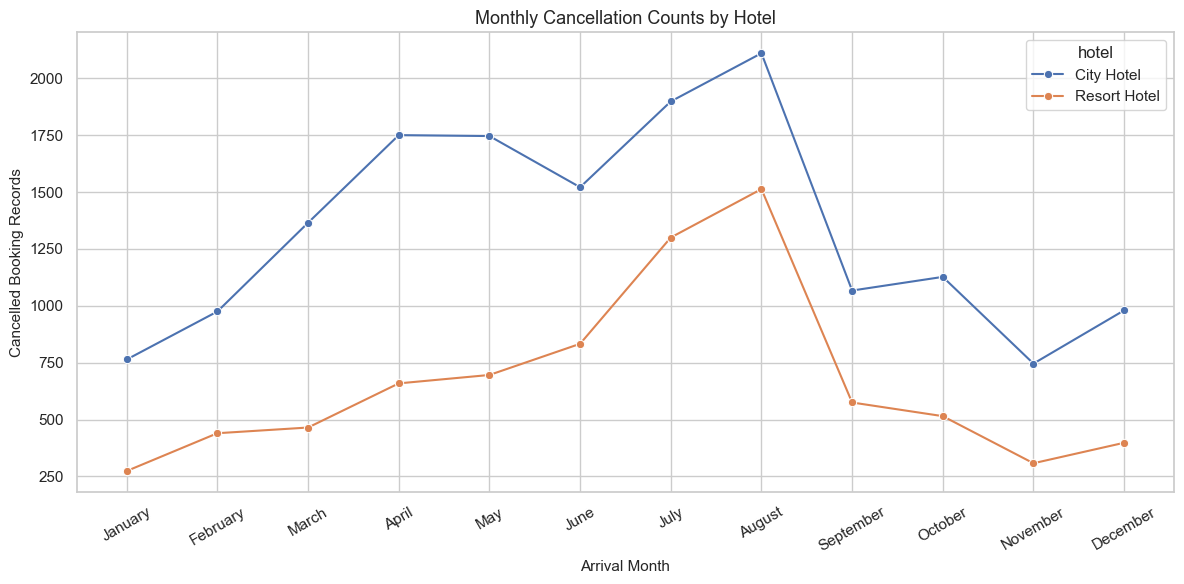

In [71]:
# Plot monthly cancellation counts by hotel
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=cancel_month,
    x='arrival_date_month',
    y='cancelled_bookings',
    hue='hotel',
    marker='o'
)

plt.title('Monthly Cancellation Counts by Hotel')
plt.xlabel('Arrival Month')
plt.ylabel('Cancelled Booking Records')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [72]:
# Identify the hotel with the highest number of cancellations
print(
    'Hotel with most cancellations:',
    by_hotel_cancel['cancelled_bookings'].idxmax()
)

# Identify the month with the highest cancellations across all hotels
print(
    'Month with most cancellations (all hotels):',
    df[df['is_canceled'] == 1]['arrival_date_month'].value_counts().idxmax()
)

Hotel with most cancellations: City Hotel
Month with most cancellations (all hotels): August


## 14. Additional cross-checks and key findings

The following tables summarize the metrics that support the business conclusions. For final interpretation, consider booking volume, cancellation rate, ADR, and length of stay together—not as a single ranking.

In [73]:
# Monthly realized booking volume
vol_totals = (
    bookings.groupby('arrival_date_month', observed=False)
    .size()
    .reindex(MONTHS)
)

# Monthly average ADR
adr_totals = (
    bookings.groupby('arrival_date_month', observed=False)['adr']
    .mean()
    .reindex(MONTHS)
)

# Monthly cancellation counts
can_totals = (
    df[df['is_canceled'] == 1]['arrival_date_month']
    .value_counts()
    .reindex(MONTHS, fill_value=0)
)

In [74]:
# Identify the busiest and slowest months by realized bookings
print(
    'Peak realized booking month:',
    vol_totals.idxmax(),
    f'({int(vol_totals.max()):,} bookings)'
)

print(
    'Lowest realized booking month:',
    vol_totals.idxmin(),
    f'({int(vol_totals.min()):,} bookings)'
)

Peak realized booking month: August (7,634 bookings)
Lowest realized booking month: January (3,655 bookings)


In [75]:
# Identify the month with the highest average ADR
print(
    'Highest overall non-cancelled monthly ADR:',
    adr_totals.idxmax(),
    f'({adr_totals.max():.2f})'
)

# Identify the month with the highest cancellations
print(
    'Month with most cancellations:',
    can_totals.idxmax(),
    f'({int(can_totals.max()):,} cancellations)'
)

Highest overall non-cancelled monthly ADR: August (147.12)
Month with most cancellations: August (3,623 cancellations)


In [76]:
# Identify the most common guest country
print(
    'Most frequent guest country:',
    country_counts.index[0],
    f'({country_counts.iloc[0]:,} non-cancelled booking records)'
)

# Identify the most common meal plan
print(
    'Most common meal plan:',
    bookings['meal'].value_counts().idxmax()
)

# Identify the most common market segment
print(
    'Most common market segment:',
    bookings['market_segment'].value_counts().idxmax()
)

Most frequent guest country: PRT (17,662 non-cancelled booking records)
Most common meal plan: BB
Most common market segment: Online TA


## 15. Key insights & business recommendations

### Key Insights Summary
- **Guests are mostly European:** Portugal (`PRT`), UK (`GBR`), France (`FRA`), Spain (`ESP`), and Germany (`DEU`) make up **~68.2%** (`42,938` of `62,949`) of non-cancelled bookings with a recorded country.
- **City vs. Resort performance:** City Hotel earns more per night (**~€108.28** vs **~€92.97** non-cancelled ADR) but also has a higher cancellation rate (**30.0%** vs **23.5%**).
- **Seasonal pricing:** Resort pricing is strongly seasonal, with ADR rising from **~€48.54** in January (`~€48.93` in November) to **~€182.10** in August; City Hotel pricing is much flatter (**~€83.18–€124.53**).
- **Peak demand & seasonality:** July and August are the busiest realized months for both hotels (`3,846` and `4,481` at City Hotel; `3,013` and `3,153` at Resort Hotel). Resort demand is sharply peaked in summer, whereas City Hotel demand forms a broad March–August plateau (`3,330–4,481` bookings/month).
- **Booking channels & segments:** Online travel agents (`Online TA`) bring **~52.7%** of non-cancelled bookings, and intermediaries overall (`Online TA` + `Offline TA/TO` / `TA/TO` channel) bring **~71.3%–75.3%**; **Direct** (`~€114.83` mean ADR) and **Online TA** (`~€114.66` mean ADR) also pay the highest ADR.
- **Special requests signal commitment:** Cancellation rate falls steadily from **33.2%** (`0` requests) down to **5.6%** (`5` requests).
- **Length of stay & meals:** City Hotel guests stay **~3 nights** (`2.99`) on average; Resort stays are longer (**~4.20** nights on average) with clear weekly and bi-weekly peaks at **7 and 14 nights**. **BB** meals dominate (**~78.8%** overall), with more Half Board (**HB**: `18.0%` vs `5.2%`) at the Resort and more no-meal (**SC**: `16.2%` vs `0.3%`) at the City Hotel.

### Strategic Recommendations
- **Hotel performance:** Compare non-cancelled booking volumes, ADR, median ADR, and average length of stay together—higher volume at City Hotel is offset by higher cancellation rates (`30.0%`) and shorter stays (`2.99` nights).
- **Seasonality:** Use the monthly volume and monthly ADR charts to align dynamic pricing and staffing with the sharp summer peak at Resort Hotel versus the broad Mar–Aug plateau at City Hotel.
- **Guest origins:** Focus destination marketing and channel partnerships on the top five European markets (`PRT`, `GBR`, `FRA`, `ESP`, `DEU`), while monitoring concentration risk.
- **Meal mix:** Align breakfast/half-board kitchen capacity and package offers with each property's meal profile (`HB` demand at Resort Hotel vs `SC` demand at City Hotel).
- **Special requests:** Encourage early preference capture during booking; while associative rather than proven causal, guests with special requests cancel far less frequently.
- **Market segments:** Prioritize high-ADR `Direct` and `Online TA` channels while using `Offline TA/TO` and `Groups` strategically during off-peak winter months.
- **Cancellation controls:** Target high-cancellation periods (July–August) and City Hotel bookings for deposit, reminder, and flexible-policy experiments.

### Limitations
1. Exact duplicate rows were removed; the dataset does not include a booking ID to prove whether identical rows are separate genuine bookings.
2. Country-level counts use booking rows as a proxy for guests.
3. ADR outliers remain in summary calculations; charts cap extreme values only to improve readability.
4. Month-of-year summaries pool years, which can hide year-specific trends.
5. Missing agent/company values are retained; they are not required for this analysis's core questions.
6. Results are descriptive and should be validated with business context before operational decisions.

## 16. Reproducibility

This project uses the CSV included in the repository. Run cells from top to bottom in Jupyter Notebook or JupyterLab. Suggested environment: Python 3.9+ with `pandas`, `numpy`, `matplotlib`, `seaborn`, `plotly`, and `pycountry`.